In [1]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
from sklearn import metrics
from PIL import Image
import json
import random
import pandas as pd
import tensorflow as tf
from keras import layers
import keras
import keras_tuner
import gc
import seaborn as sn
import pandas as pd
import matplotlib.pyplot as plt

hp = keras_tuner.HyperParameters()

print(tf.__version__)
print(tf.config.list_physical_devices())

2.10.0
[PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
train64_ds, valid64_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_64_train/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    validation_split=0.2,
    subset='both',
    seed=42
)
test64_ds = keras.utils.image_dataset_from_directory(
    directory='./data/images_64_test/',
    labels='inferred',
    label_mode='binary',
    batch_size=16,
    image_size=(64,64),
    seed=42
)

def process(image,label):
    image = tf.cast(image/255. ,tf.float32)
    return image,label
train64_ds = train64_ds.map(process)
valid64_ds = valid64_ds.map(process)
test64_ds = test64_ds.map(process)

Found 5019 files belonging to 2 classes.
Using 4016 files for training.
Using 1003 files for validation.
Found 1209 files belonging to 2 classes.


In [3]:
# def build_model64(hp):
#     model = keras.models.Sequential()
#     model.add(keras.Input(shape=(64,64,3)))

#     for i in range(hp.Int("num_layers", 1, 3)):
#         model.add(layers.Conv2D(
#             filters=hp.Int(f"filters_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
#             kernel_size=8, 
#             activation='relu', padding="same"))
#         model.add(layers.MaxPooling2D(pool_size=2, strides=2))

#     model.add(layers.Flatten())
#     for i in range(hp.Int("dense_layers", 1, 3)):
#         model.add(layers.Dense(
#             units=hp.Int(f"dense_{i}", min_value=8, max_value=64, step=2, sampling="log"), 
#             activation="relu"))

#     model.add(layers.Dense(units=1, activation='sigmoid'))

#     model.compile(
#         loss=tf.keras.losses.binary_crossentropy,
#         optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
#         metrics=[keras.metrics.binary_accuracy]
#         # metrics=[tf.keras.metrics.RecallAtPrecision(0.8)]
#     )
#     return model
# # tmodel=build_model
# # print(tmodel)

In [4]:
# tuner = keras_tuner.RandomSearch(
#     hypermodel=build_model64,
#     objective="val_binary_accuracy",
#     max_trials=5,
#     overwrite=True,
#     directory="./models/",
#     project_name="model64",
# )
# # tuner = keras_tuner.Hyperband(
# #     hypermodel=build_model,
# #     objective='val_binary_accuracy',
# #     # objective=keras_tuner.Objective("val_recall_at_precision", direction="max"),
# #     max_epochs=50,
# #     factor=3,
# #     overwrite=True,
# #     directory="./models/",
# #     project_name="model2",
# #     seed=42
# # )
# stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy",
#                                            patience=5)

In [5]:
# tuner.search(
#     train64_ds, 
#     epochs=50, 
#     validation_data=valid64_ds, 
#     callbacks=[stop_early]
#     )

Trial 5 Complete [00h 00m 24s]
val_binary_accuracy: 0.736697256565094

Best val_binary_accuracy So Far: 0.868807315826416
Total elapsed time: 00h 01m 55s
INFO:tensorflow:Oracle triggered exit


In [6]:
# models = tuner.get_best_models(2)
# best_model = models[0]
# best_model.build()
# best_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         1544      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 32)                262176    
                                                                 
 dense_1 (Dense)             (None, 8)                 264       
                                                                 
 dense_2 (Dense)             (None, 8)                 72        
                                                        

In [7]:
# best_model.evaluate(test64_ds)

84/84 [==============================] - 1s 10ms/step - loss: 0.3319 - binary_accuracy: 0.8851


[0.3319053649902344, 0.8850746154785156]

In [16]:
# best_model.save("./trained_models/model64")

INFO:tensorflow:Assets written to: ./trained_models/model64\assets


INFO:tensorflow:Assets written to: ./trained_models/model64\assets


In [3]:
# saved_model64 = keras.models.load_model("./trained_models/model64/")
# saved_model64.evaluate(test64_ds)
# saved_model64.summary()

76/76 [==============================] - 5s 6ms/step - loss: 0.5817 - binary_accuracy: 0.9165
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         1544      
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 flatten (Flatten)           (None, 8192)              0         
                                                                 
 dense (Dense)               (None, 32)                262176    
                                                                 
 dense_1 (Dense)             (None, 8)                 264       
                                                                 
 dense_2 (Dense)            

In [3]:
def test_model(model, dataset):
    filtered_data = []
    TP = 0
    FP = 0
    TN = 0
    FN = 0
    for i, (images, label) in enumerate(dataset, 0):
        output = model(images)
        prediction = output.numpy()
        for i in range(len(prediction)):
            if prediction[i][0] > 0.4:
                if label[i]== 1:
                    TP += 1
                else: FP += 1
                filtered_data.append(images[i])
                # print(prediction[i], label[i])
            else:
                if label[i]== 1:
                    FN += 1
                else: TN += 1

    f1 = (2*TP)/(2*TP+FP+FN)
    return filtered_data, TP, FP, TN, FN, f1

In [4]:
# #Correct model
# model = keras.models.Sequential()
# model.add(keras.Input(shape=(64,64,3)))
# model.add(layers.Conv2D(filters=8,kernel_size=8, 
#                         activation='relu', padding='same'))
# model.add(layers.MaxPool2D(pool_size=2, strides=2))
# model.add(layers.Flatten())
# model.add(layers.Dense(units=32, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))
# model.add(layers.Dense(units=8, activation="relu"))

# model.add(layers.Dense(units=1, activation="sigmoid"))

model = keras.models.Sequential()
model.add(keras.Input(shape=(64,64,3)))
model.add(layers.Conv2D(filters=8, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=16, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))
model.add(layers.Conv2D(filters=32, kernel_size=3, activation='relu', padding='same'))
model.add(layers.MaxPool2D(pool_size=2, strides=2))

model.add(layers.Flatten())

model.add(layers.Dense(units=64, activation='relu'))
model.add(layers.Dense(units=1, activation='sigmoid'))


model.compile(
        loss=tf.keras.losses.binary_crossentropy,
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        metrics=[keras.metrics.binary_accuracy]
    )

stop_early = keras.callbacks.EarlyStopping(monitor="val_binary_accuracy", patience=5)

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 64, 8)         224       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 32, 8)        0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 32, 16)        1168      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 16, 16)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 16, 16, 32)        4640      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 8, 8, 32)         0

In [5]:
history = model.fit(
    train64_ds, 
    epochs=50, 
    validation_data=valid64_ds, 
    callbacks=[stop_early],
    # class_weight= {0: 0.9, 1: 1}
    )

Epoch 1/50
251/251 [==============================] - 7s 11ms/step - loss: 0.5800 - binary_accuracy: 0.7420 - val_loss: 0.5784 - val_binary_accuracy: 0.7527
Epoch 2/50
251/251 [==============================] - 3s 11ms/step - loss: 0.5735 - binary_accuracy: 0.7420 - val_loss: 0.5673 - val_binary_accuracy: 0.7527
Epoch 3/50
251/251 [==============================] - 3s 10ms/step - loss: 0.5361 - binary_accuracy: 0.7515 - val_loss: 0.3403 - val_binary_accuracy: 0.8654
Epoch 4/50
251/251 [==============================] - 3s 11ms/step - loss: 0.3027 - binary_accuracy: 0.8840 - val_loss: 0.2767 - val_binary_accuracy: 0.9003
Epoch 5/50
251/251 [==============================] - 3s 12ms/step - loss: 0.2149 - binary_accuracy: 0.9153 - val_loss: 0.2453 - val_binary_accuracy: 0.9143
Epoch 6/50
251/251 [==============================] - 3s 12ms/step - loss: 0.1725 - binary_accuracy: 0.9343 - val_loss: 0.2340 - val_binary_accuracy: 0.9043
Epoch 7/50
251/251 [==============================] - 3s 1

In [6]:
model.save("./trained_models/model64_test")

INFO:tensorflow:Assets written to: ./trained_models/model64_test\assets


INFO:tensorflow:Assets written to: ./trained_models/model64_test\assets


f1-score: 0.8547249647390691


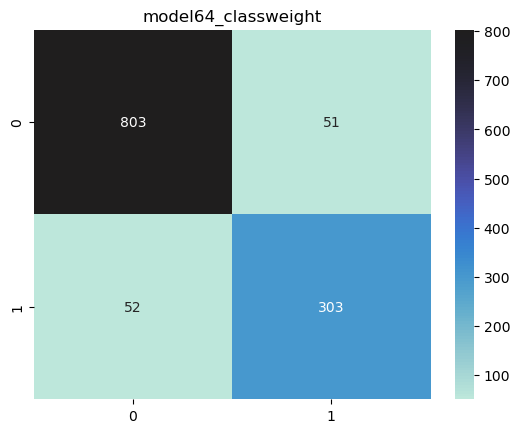

In [29]:
filtered_data, TP, FP, TN, FN, f1 = test_model(model, test64_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model64_classweight')
plt.savefig('./documentation/model64_classweight.png')
plt.show()

f1-score: 0.8559782608695652


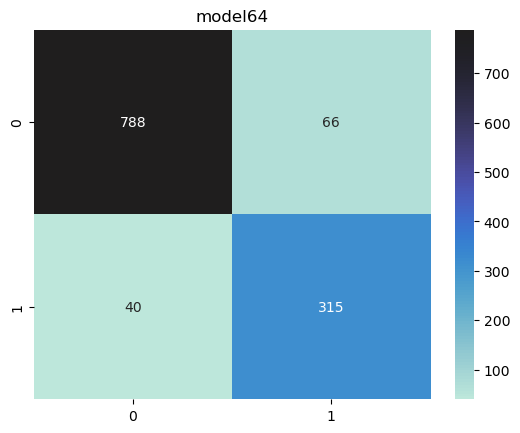

In [28]:
saved_model64 = keras.models.load_model("./trained_models/model64/")
# saved_model64.save("./trained_models/model64_2")
filtered_data, TP, FP, TN, FN, f1 = test_model(saved_model64, test64_ds)
print(f'f1-score: {f1}')

array = [[TN, FP],
        [FN, TP]]

df_cm = pd.DataFrame(array, range(2), range(2))
sn.heatmap(df_cm, annot=True, center=TN, fmt='g')
plt.title('model64')

plt.show()